# Weighting returns by average uniqueness

This native Julia companion uses the same public minute records, fifteen-minute resampling, inclusive event spans, and public weighting formulas. Sequential sampling retains the original conditional uniqueness rule and 80 paired repetitions. Its local Xoshiro generator uses seed 20260926; Julia and NumPy streams differ, so every selection and primitive uniform draw is saved for independent replay. Plots use the requested dark theme, with results saved under `outputs/julia`.

An active event receives an equal share of a price interval, and its average share over its life is its average uniqueness:

$$
u_{ti}=\frac{I_{ti}}{c_t},\qquad
\overline u_i=\frac{\sum_t u_{ti}}{\sum_t I_{ti}}.
$$

Here, $u_{ti}$ is event $i$'s uniqueness at time $t$; $I_{ti}$ is its activity indicator; $c_t$ is concurrency. $\overline u_i\in[0,1]$ is average uniqueness; the denominator $\sum_t I_{ti}$ is event $i$'s length.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("07_overlapping_information_weights");
using CSV, Printf
using RiskLabAI.Data: daily_volatility_with_log_returns,symmetric_cusum_filter,cusum_filter_events_dynamic_threshold,vertical_barrier,triple_barrier,meta_labeling,calculate_t_value_linear_regression,find_trend_using_trend_scanning
raw = load_binance()
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
close_index,close_prices = raw.time,raw.close
log_price = log.(close_prices)
price_positions = Dict(time=>position for (position,time) in enumerate(close_index))
violet = "#C084FC"

function count_histogram!(figure,values,bins;color,label=false,alpha=.75)
    edges = collect(range(minimum(values),maximum(values);length=bins+1))
    counts = [count(value->edges[index]<=value && (value<edges[index+1] || index==bins && value==edges[end]),values) for index in 1:bins]
    bar!(figure,(edges[1:end-1].+edges[2:end])./2,counts;bar_width=diff(edges),color,fillalpha=alpha,linecolor=color,label)
    ylims!(figure,0.,1.1max(maximum(counts),last(ylims(figure))))
    return DataFrame(left=edges[1:end-1],right=edges[2:end],count=counts)
end

function box_summary!(figure,groups,colors)
    for (index,values) in enumerate(groups)
        lower,middle,upper = quantile(values,[.25,.5,.75])
        spread = upper-lower
        bottom = minimum(values[values.>=lower-1.5spread])
        top = maximum(values[values.<=upper+1.5spread])
        plot!(figure,Shape([index-.25,index+.25,index+.25,index-.25],[lower,lower,upper,upper]);color=colors[index],fillalpha=.65,linecolor=palette.text,label=false)
        plot!(figure,[index-.25,index+.25],[middle,middle];color=palette.text,label=false)
        plot!(figure,[index,index],[bottom,lower];color=palette.text,label=false)
        plot!(figure,[index,index],[upper,top];color=palette.text,label=false)
        for height in (bottom,top)
            plot!(figure,[index-.12,index+.12],[height,height];color=palette.text,label=false)
        end
    end
    return figure
end
using RiskLabAI.Data: calculate_average_uniqueness,calculate_time_decay,expand_label_for_meta_labeling,sample_weight_absolute_return_meta_labeling,sequential_bootstrap
minute_close = copy(close_prices)
resampled = combine(groupby(DataFrame(time=floor.(raw.time,Minute(15)),price=raw.close),:time;sort=true),:price=>last=>:close)
close_index,close_prices = resampled.time,resampled.close
log_price = log.(close_prices)
price_positions = Dict(time=>position for (position,time) in enumerate(close_index))
span = 100
volatility = daily_volatility_with_log_returns(close_index,close_prices;span)
volatility_lookup = Dict(zip(volatility.index,volatility.volatility))

function dynamic_threshold_events(multiplier)
    selected = findall(isfinite,volatility.volatility)
    positions = [price_positions[volatility.index[index]] for index in selected]
    aligned = vcat(first(positions)-1,positions)
    return cusum_filter_events_dynamic_threshold(close_index[aligned],log_price[aligned],vcat(NaN,multiplier.*volatility.volatility[selected]))
end
event_times = dynamic_threshold_events(1.)
vertical_times = vertical_barrier(close_index,event_times,1)
ending_lookup = Dict(zip(vertical_times.event,vertical_times.barrier))
event_times = [time for time in event_times if haskey(ending_lookup,time) && isfinite(get(volatility_lookup,time,NaN))]
event_ends = [ending_lookup[time] for time in event_times]
start_positions,end_positions = [price_positions[time] for time in event_times],[price_positions[time] for time in event_ends]
indicator_matrix = Int[time>=start && time<=ending for time in close_index,(start,ending) in zip(event_times,event_ends)]
event_duration = vec(sum(indicator_matrix;dims=1))
matrix_concurrency = vec(sum(indicator_matrix;dims=2))
active_concurrency = matrix_concurrency[matrix_concurrency.>0]
library_concurrency = expand_label_for_meta_labeling(close_index,event_times,event_ends,event_times);


## Exact Allocation of Shared Information

In [2]:
controlled_matrix = [1 0 1;1 1 1;1 1 0;0 1 0]
controlled_uniqueness = calculate_average_uniqueness(controlled_matrix)
controlled_table = DataFrame("Event"=>["Event A","Event B","Event C"],"Average uniqueness"=>controlled_uniqueness,"Exact value"=>["4/9","11/18","5/12"])
average_uniqueness = calculate_average_uniqueness(indicator_matrix)
active_records = count(>(0),matrix_concurrency)
allocated_records = sum(average_uniqueness.*event_duration)
uniqueness_summary = DataFrame("Summary"=>["Smallest","10th percentile","Middle value","Mean","90th percentile","Largest","Allocated active records"],"Value"=>[minimum(average_uniqueness),quantile(average_uniqueness,.1),median(average_uniqueness),mean(average_uniqueness),quantile(average_uniqueness,.9),maximum(average_uniqueness),allocated_records])
save_table(controlled_table,paths,"controlled_uniqueness";caption="Exact average uniqueness for a three-event example.",label="tab:chapter6-controlled-uniqueness")
save_table(uniqueness_summary,paths,"uniqueness_summary";caption="Average uniqueness in the public January event sample.",label="tab:chapter6-uniqueness-summary")


Row,Event,Average uniqueness,Exact value
,String,Float64,String
1,Event A,0.444444,4/9
2,Event B,0.611111,11/18
3,Event C,0.416667,5/12


Row,Summary,Value
,String,Float64
1,Smallest,0.104516
2,10th percentile,0.115052
3,Middle value,0.184855
4,Mean,0.21665
5,90th percentile,0.376151
6,Largest,0.814433
7,Allocated active records,2795.0


Every active price interval contributes one full unit of information, divided among its active events without loss or duplication:

$$
\sum_{i=1}^{n}u_{ti}=\mathbf 1\{c_t>0\},\qquad
\sum_{i=1}^{n}L_i\overline u_i=\#\{t:c_t>0\}.
$$

Here, $n$ is the number of events; $u_{ti}$ is event-level uniqueness; $c_t$ is concurrency. $L_i=\sum_t I_{ti}$ is event length; $\overline u_i$ is average uniqueness; $\#\{t:c_t>0\}$ counts active intervals.

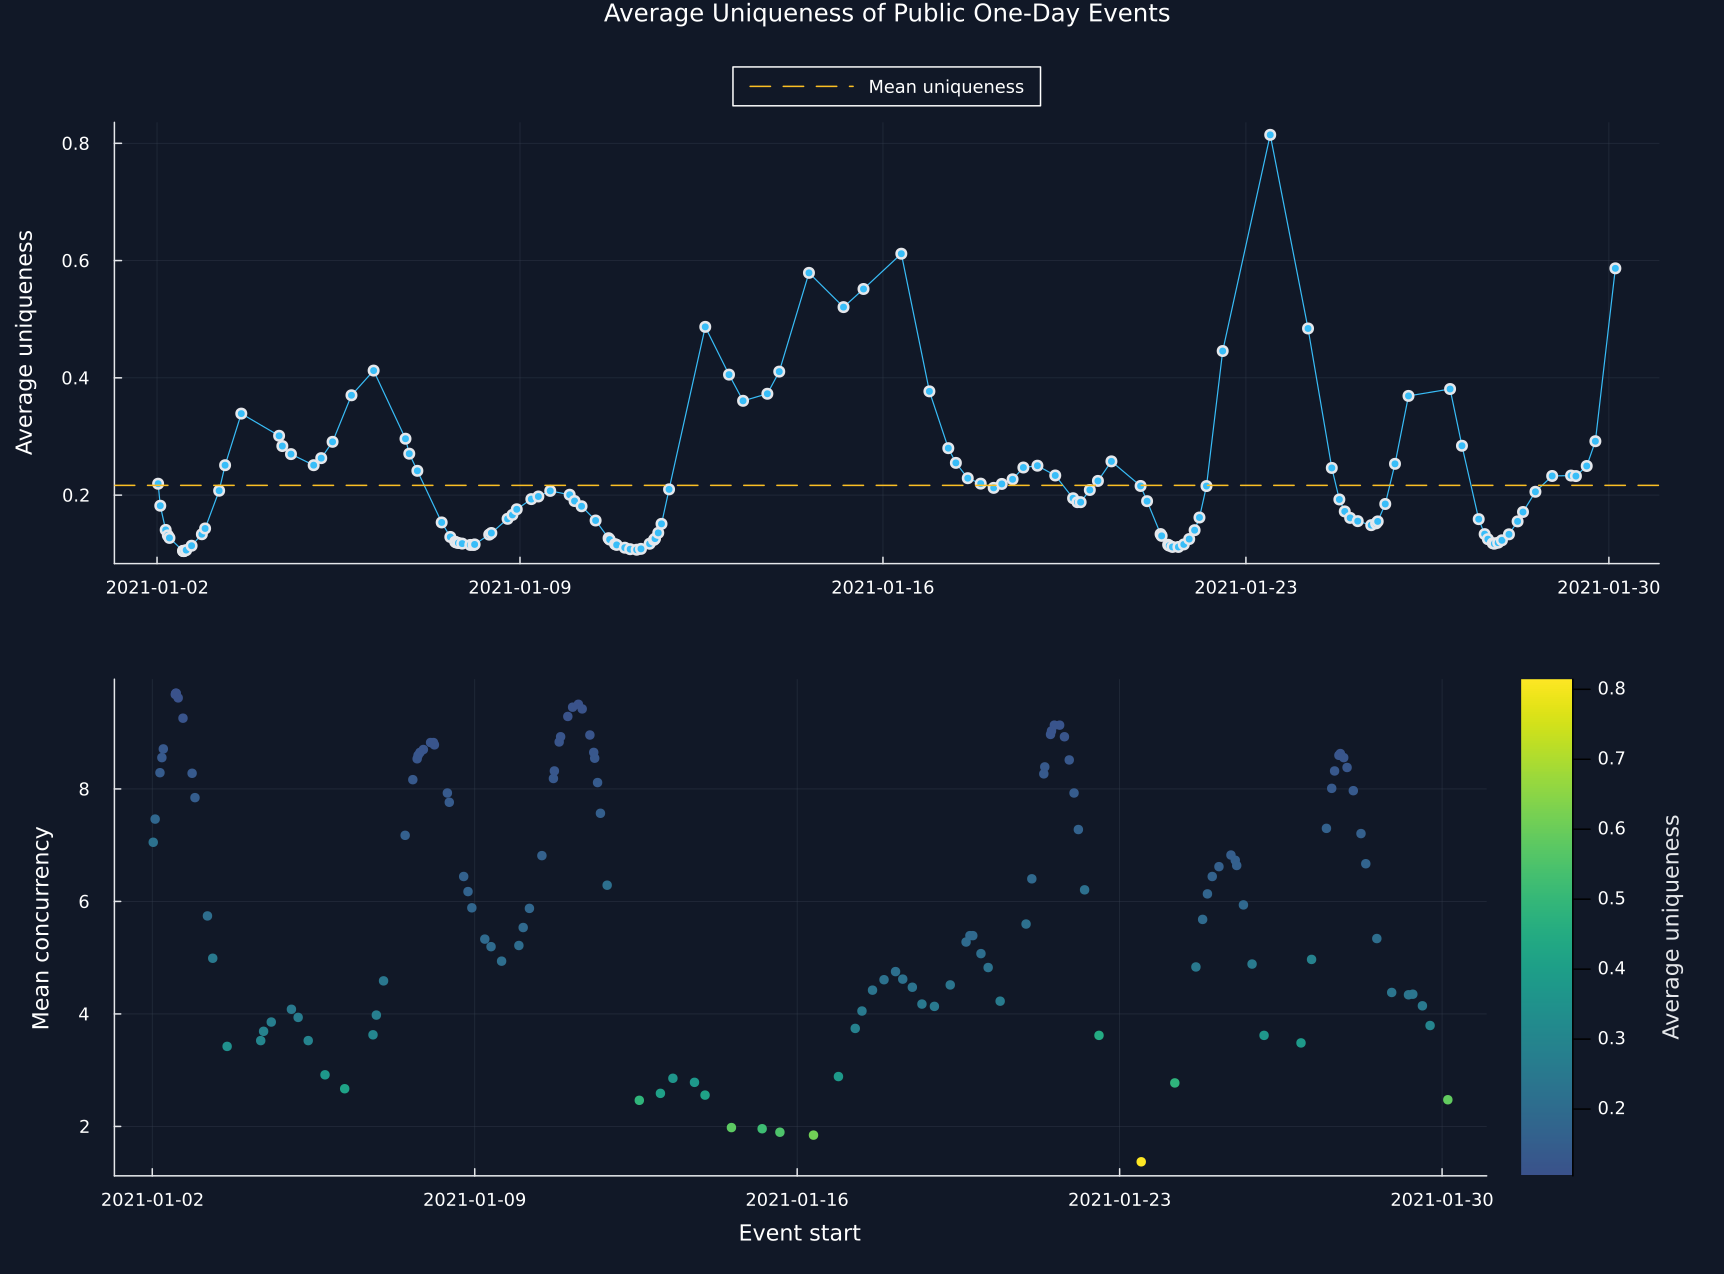

In [3]:
interval_uniqueness = indicator_matrix./max.(matrix_concurrency,1)
p1 = plot(event_times,average_uniqueness;color=palette.cyan,marker=:circle,markersize=3.5,linewidth=.8,ylabel="Average uniqueness",title="Average Uniqueness of Public One-Day Events",label=false,legend=:outertop)
hline!(p1,[mean(average_uniqueness)];color=palette.amber,linestyle=:dash,linewidth=1.,label="Mean uniqueness")
mean_concurrency_by_event = [mean(matrix_concurrency[left:right]) for (left,right) in zip(start_positions,end_positions)]
p2 = scatter(event_times,mean_concurrency_by_event;marker_z=average_uniqueness,color=cgrad([cgrad(:viridis)[fraction] for fraction in range(.25,1.;length=100)]),markersize=3.5,markerstrokewidth=0,ylabel="Mean concurrency",xlabel="Event start",colorbar_title="Average uniqueness",label=false)
save_figure(plot(p1,p2;layout=(2,1),link=:x,size=(1150,850)),paths,"uniqueness_profile")


## Return Attribution

An event receives its share of absolute price movement, then all event weights are scaled to have average one:

$$
\widetilde w_i=\sum_t I_{ti}\frac{|r_t|}{c_t},\qquad
w_i=n\frac{\widetilde w_i}{\sum_{j=1}^{n}\widetilde w_j},\qquad
\sum_{i=1}^{n}w_i=n.
$$

Here, $r_t=\log P_t-\log P_{t-1}$ is the log return; $I_{ti}$ is the event indicator; $c_t$ is concurrency. $\widetilde w_i$ is unscaled attributed movement; $w_i$ is the normalized weight; $n$ is the number of events.

Row,Event start,Event end,Average uniqueness,Absolute movement,Normalized attribution weight
,DateTime,DateTime,Float64,Float64,Float64
1,2021-01-12T13:45:00,2021-01-13T13:45:00,0.486942,0.736802,3.14541
2,2021-01-15T15:00:00,2021-01-16T15:00:00,0.551546,0.589612,2.70985
3,2021-01-15T05:45:00,2021-01-16T05:45:00,0.520619,0.547672,2.42937
4,2021-01-16T08:30:00,2021-01-17T08:30:00,0.611684,0.456017,2.24491
5,2021-01-06T04:15:00,2021-01-07T04:15:00,0.412371,0.581643,2.07812
6,2021-01-03T15:00:00,2021-01-04T15:00:00,0.339003,0.698836,2.06035
7,2021-01-13T00:45:00,2021-01-14T00:45:00,0.405498,0.571932,2.0227
8,2021-01-04T08:30:00,2021-01-05T08:30:00,0.301203,0.776846,2.01428


Row,Summary,Value
,String,Float64
1,Smallest weight,0.425768
2,Middle weight,0.788215
3,Mean weight,1.0
4,Largest weight,3.14541
5,Uniqueness-weight correlation,0.741252
6,Eight largest weights' share,0.140639


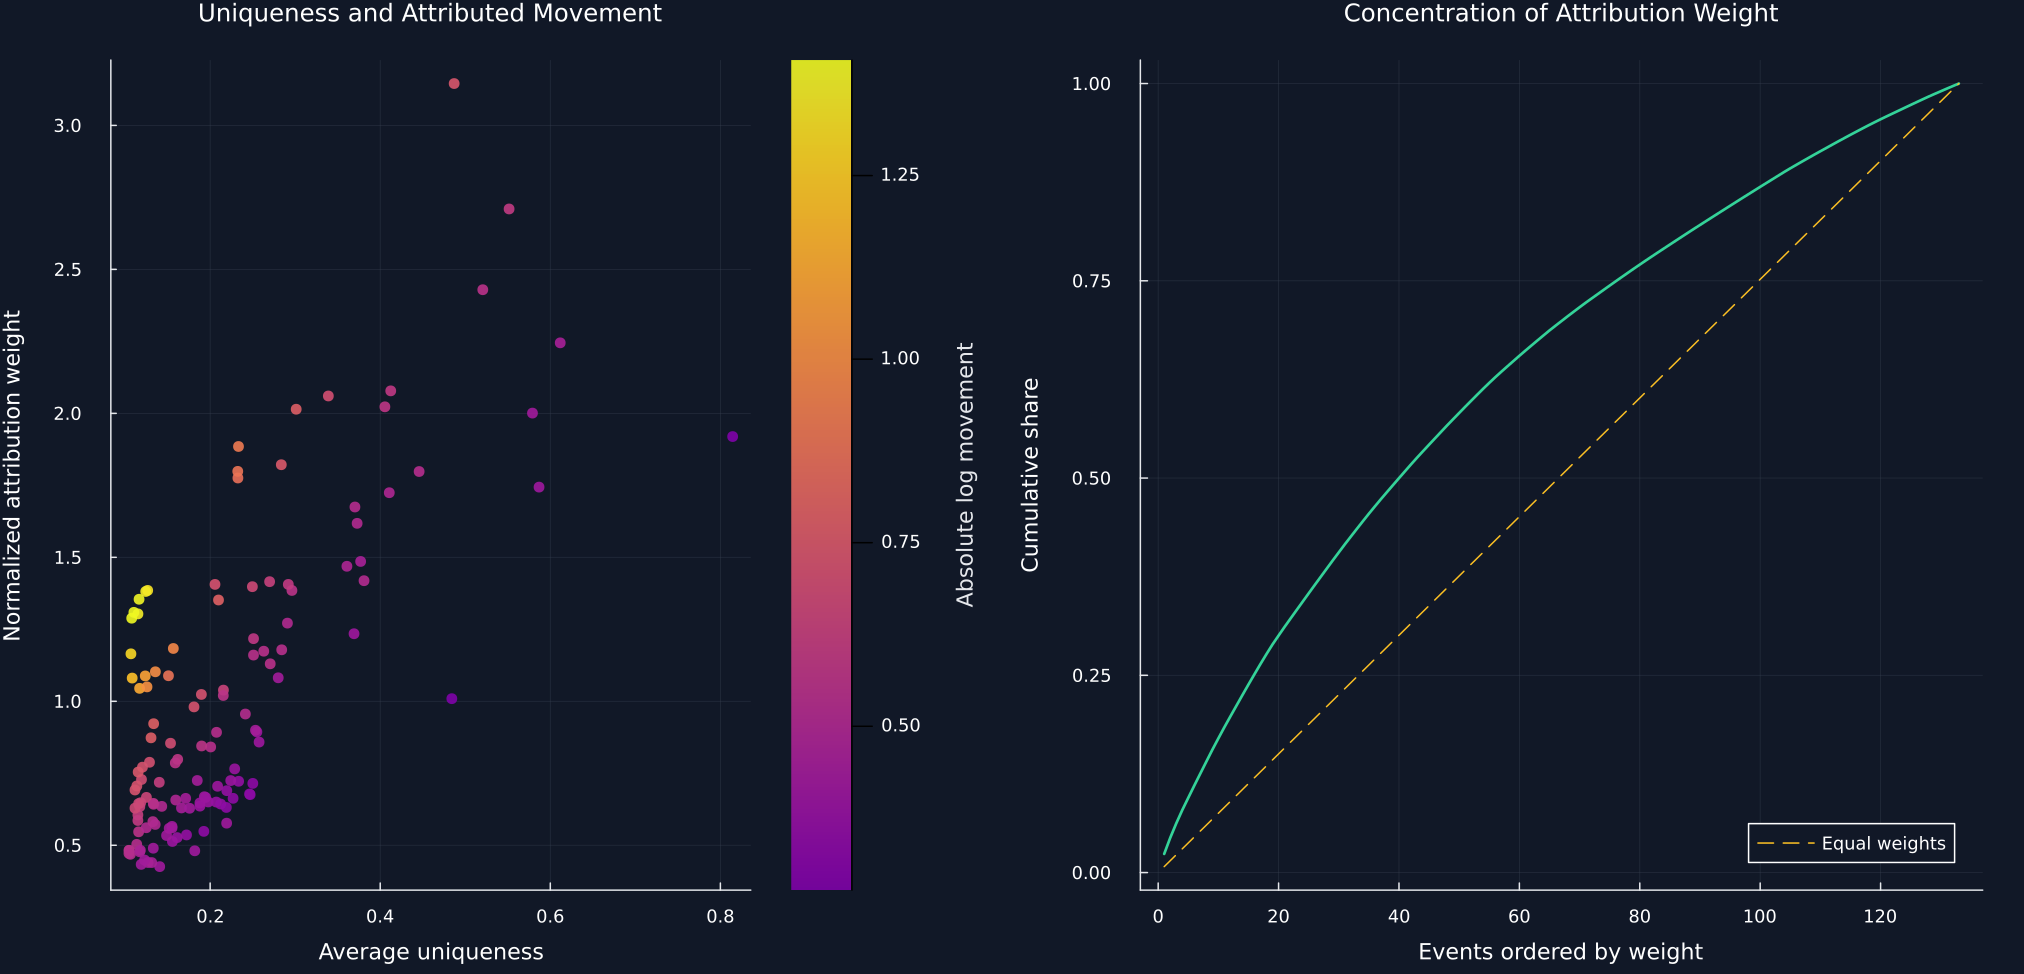

In [4]:
attribution_weights = sample_weight_absolute_return_meta_labeling(event_times,event_ends,close_index,close_prices,event_times)
absolute_log_return = vcat(NaN,abs.(diff(log_price)))
manual_raw = [sum(absolute_log_return[left:right]./matrix_concurrency[left:right]) for (left,right) in zip(start_positions,end_positions)]
manual_weights = manual_raw.*length(manual_raw)./sum(manual_raw)
attributed_movement = [sum(absolute_log_return[left:right]) for (left,right) in zip(start_positions,end_positions)]
event_results = DataFrame("Event start"=>event_times,"Event end"=>event_ends,"Average uniqueness"=>average_uniqueness,"Absolute movement"=>attributed_movement,"Normalized attribution weight"=>attribution_weights)
top_weights = event_results[sortperm(attribution_weights;rev=true)[1:8],:]
weight_summary = DataFrame("Summary"=>["Smallest weight","Middle weight","Mean weight","Largest weight","Uniqueness-weight correlation","Eight largest weights' share"],"Value"=>[minimum(attribution_weights),median(attribution_weights),mean(attribution_weights),maximum(attribution_weights),cor(average_uniqueness,attribution_weights),sum(top_weights[!,"Normalized attribution weight"])/sum(attribution_weights)])
save_table(top_weights,paths,"attribution_weight_summary";caption="Eight events with the largest normalized attribution weights.",label="tab:chapter6-attribution-weights")
save_table(weight_summary,paths,"attribution_numeric_summary")
save_data(event_results,paths,"attribution_event_results")
save_data(DataFrame(event=collect(eachindex(event_times)),mean_concurrency=mean_concurrency_by_event,raw_attributed_movement=manual_raw,manual_weight=manual_weights),paths,"independent_attribution")
p1 = scatter(average_uniqueness,attribution_weights;marker_z=attributed_movement,color=cgrad([cgrad(:plasma)[fraction] for fraction in range(.25,1.;length=100)]),markersize=4,alpha=.9,markerstrokewidth=0,xlabel="Average uniqueness",ylabel="Normalized attribution weight",title="Uniqueness and Attributed Movement",colorbar_title="Absolute log movement",label=false)
ordered_weights = sort(attribution_weights;rev=true)
p2 = plot(eachindex(ordered_weights),cumsum(ordered_weights)./sum(ordered_weights);color=palette.green,linewidth=1.8,xlabel="Events ordered by weight",ylabel="Cumulative share",title="Concentration of Attribution Weight",label=false,legend=:bottomright)
plot!(p2,[1,length(ordered_weights)],[1/length(ordered_weights),1.];color=palette.amber,linestyle=:dash,linewidth=1.,label="Equal weights")
save_figure(plot(p1,p2;layout=(1,2),size=(1350,650)),paths,"attribution_weights")


## Weight Distribution Through Time

Row,Summary,Normalized attribution weight
,String,Float64
1,Smallest,0.425768
2,10th percentile,0.50516
3,25th percentile,0.634258
4,Middle value,0.788215
5,75th percentile,1.2886
6,90th percentile,1.79348
7,Largest,3.14541
8,Mean,1.0


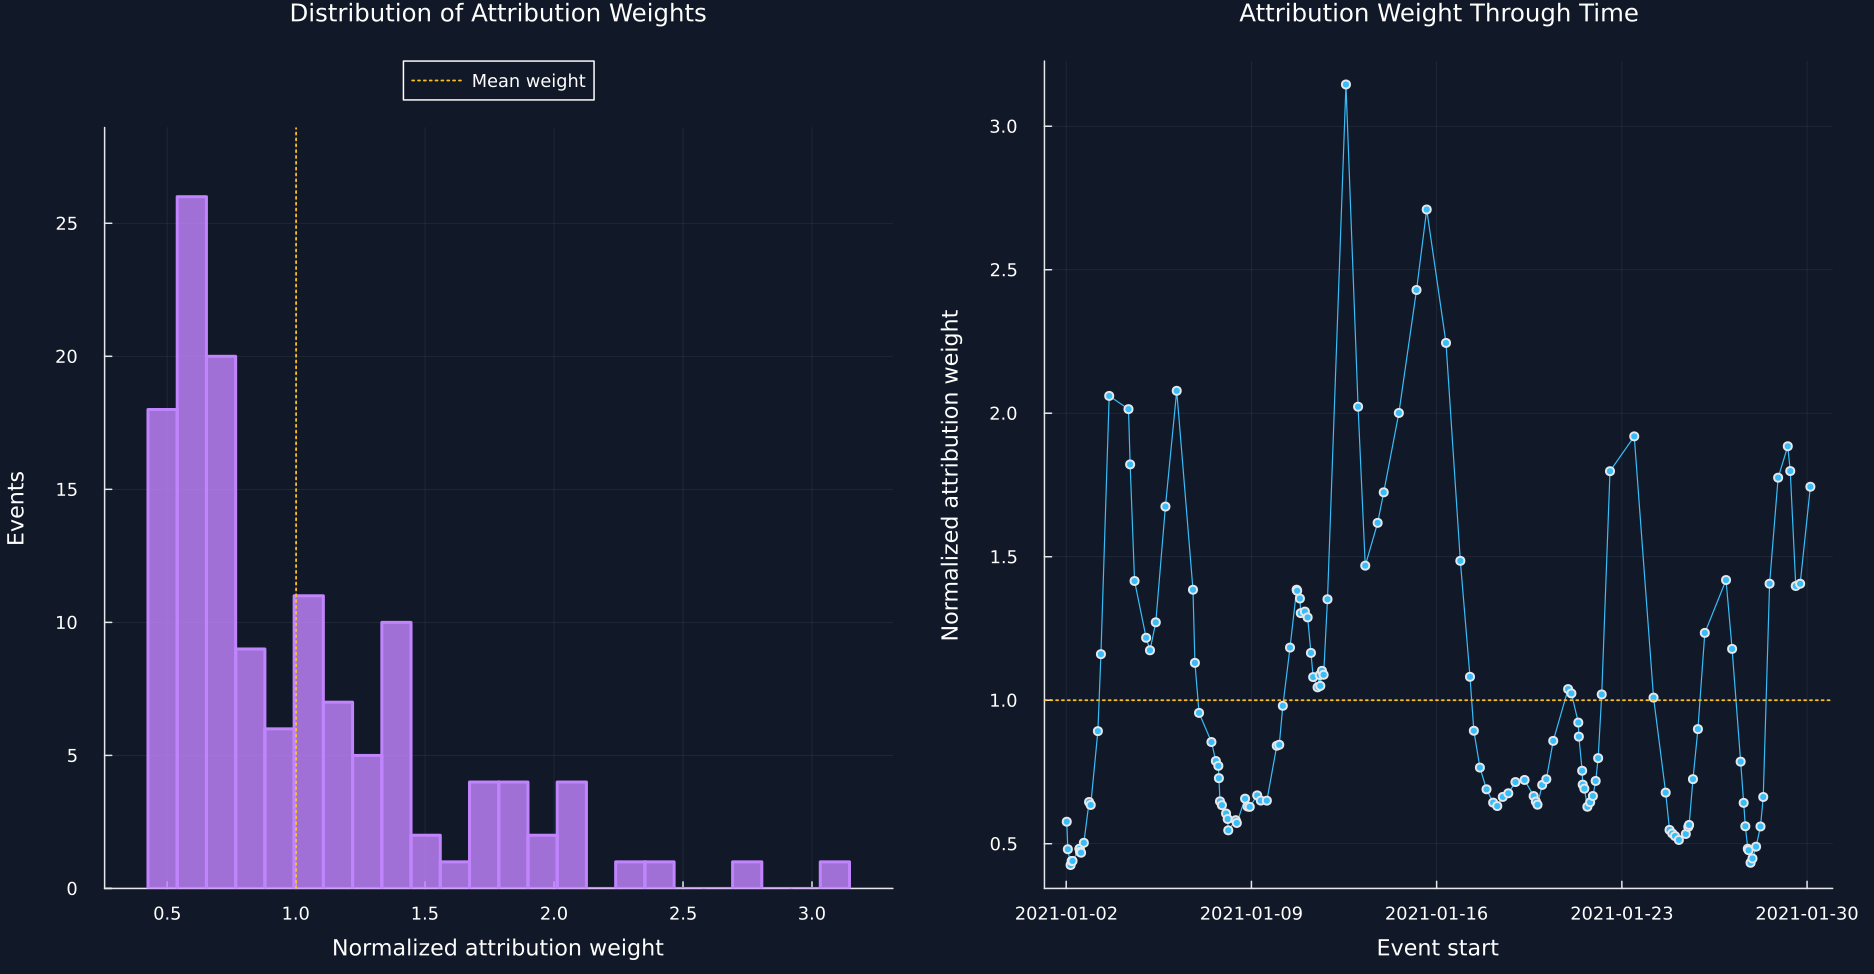

In [5]:
weight_distribution_summary = DataFrame("Summary"=>["Smallest","10th percentile","25th percentile","Middle value","75th percentile","90th percentile","Largest","Mean"],"Normalized attribution weight"=>[minimum(attribution_weights),quantile(attribution_weights,.1),quantile(attribution_weights,.25),median(attribution_weights),quantile(attribution_weights,.75),quantile(attribution_weights,.9),maximum(attribution_weights),mean(attribution_weights)])
save_table(weight_distribution_summary,paths,"attribution_weight_distribution";caption="Distribution of normalized absolute-return attribution weights.",label="tab:chapter6-attribution-weight-distribution")
p1 = plot(;title="Distribution of Attribution Weights",xlabel="Normalized attribution weight",ylabel="Events",legend=:outertop)
histogram_data = count_histogram!(p1,attribution_weights,24;color=violet,alpha=.82)
vline!(p1,[1.];color=palette.amber,linewidth=1.2,linestyle=:dot,label="Mean weight")
p2 = plot(event_times,attribution_weights;color=palette.cyan,marker=:circle,markersize=3,linewidth=.8,title="Attribution Weight Through Time",xlabel="Event start",ylabel="Normalized attribution weight",label=false)
hline!(p2,[1.];color=palette.amber,linewidth=1.2,linestyle=:dot,label=false)
save_data(histogram_data,paths,"attribution_weight_histogram")
save_figure(plot(p1,p2;layout=(1,2),size=(1250,650)),paths,"attribution_weight_distribution")


## Tests

In [6]:
@assert length(event_times)==133
@assert isapprox(controlled_uniqueness,[4/9,11/18,5/12])
@assert all(0 .<= average_uniqueness .<= 1)
@assert all(isapprox.(vec(sum(interval_uniqueness;dims=2))[matrix_concurrency.>0],1.))
@assert all(iszero,vec(sum(interval_uniqueness;dims=2))[matrix_concurrency.==0])
@assert isapprox(allocated_records,active_records)
@assert active_records==2795
@assert isapprox(attribution_weights,manual_weights)
@assert isapprox(sum(attribution_weights),length(event_times))
@assert isapprox(mean(attribution_weights),1.)
@assert all(attribution_weights.>0)
@assert cor(average_uniqueness,attribution_weights)>.70
@assert issorted(top_weights[!,"Normalized attribution weight"];rev=true)
@assert all(event_results[!,"Event end"].>event_results[!,"Event start"])
@assert nrow(weight_distribution_summary)==8
@assert isapprox(last(weight_distribution_summary[!,"Normalized attribution weight"]),1.)
@assert isfile(joinpath(paths.figures,"attribution_weight_distribution.pdf"))
@assert isfile(joinpath(paths.tables,"attribution_weight_distribution.tex"))
